# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


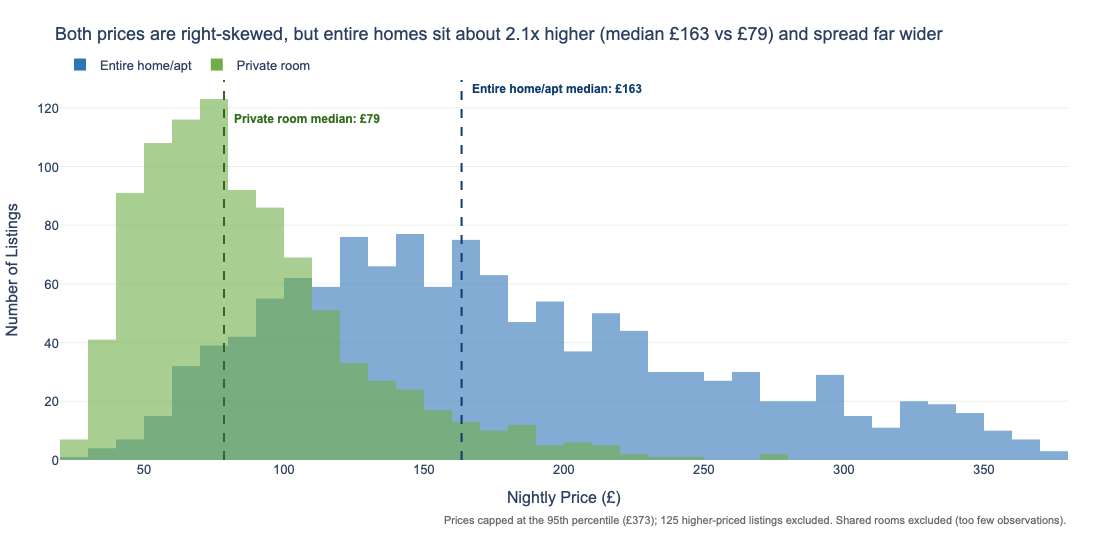

In [3]:
# Task 1 — Overlaid histogram: Entire home/apt vs Private room (capped at 95th percentile)
d1 = df_cap[df_cap['room_type'].isin(['Entire home/apt', 'Private room'])]

colours = {'Entire home/apt': '#2E75B6', 'Private room': '#70AD47'}   # colour = room type, consistent with lecture
line_colours = {'Entire home/apt': '#0B3C6E', 'Private room': '#2F6B1A'}  # darker shade of same hue for the median lines
medians = d1.groupby('room_type')['price'].median()

fig = px.histogram(
    data_frame=d1, x='price', color='room_type',
    nbins=50, barmode='overlay', opacity=0.6,
    color_discrete_map=colours,
    category_orders={'room_type': ['Entire home/apt', 'Private room']},
    labels={'price': 'Nightly Price (£)', 'count': 'Number of Listings', 'room_type': ''},
    height=550
)

# One median line per room type, annotated (offset vertically so labels don't collide)
for room, yanchor, yshift in [('Entire home/apt', 'top', 0), ('Private room', 'top', -30)]:
    m = medians[room]
    fig.add_vline(
        x=m, line_dash='dash', line_color=line_colours[room], line_width=2,
        annotation=dict(text=f'<b>{room} median: £{m:.0f}</b>',
                        font=dict(color=line_colours[room], size=12),
                        xanchor='left', yanchor=yanchor, xshift=8, yshift=yshift)
    )

# Disclose the outlier cap
fig.add_annotation(
    xref='paper', yref='paper', x=1, y=-0.18, showarrow=False, xanchor='right',
    text=f'Prices capped at the 95th percentile (£{p95:.0f}); {len(df) - len(df_cap):,} higher-priced listings excluded. Shared rooms excluded (too few observations).',
    font=dict(size=11, color='#666666')
)

gap = medians['Entire home/apt'] / medians['Private room']
fig.update_layout(
    title=f"Both prices are right-skewed, but entire homes sit about {gap:.1f}x higher (median £{medians['Entire home/apt']:.0f} vs £{medians['Private room']:.0f}) and spread far wider",
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    yaxis=dict(gridcolor='#EEEEEE', title='Number of Listings'),
    xaxis=dict(showgrid=False),
    legend=dict(orientation='h', x=0, y=1.08, title=''),
    margin=dict(l=60, r=40, t=80, b=90)
)
fig.show()


## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

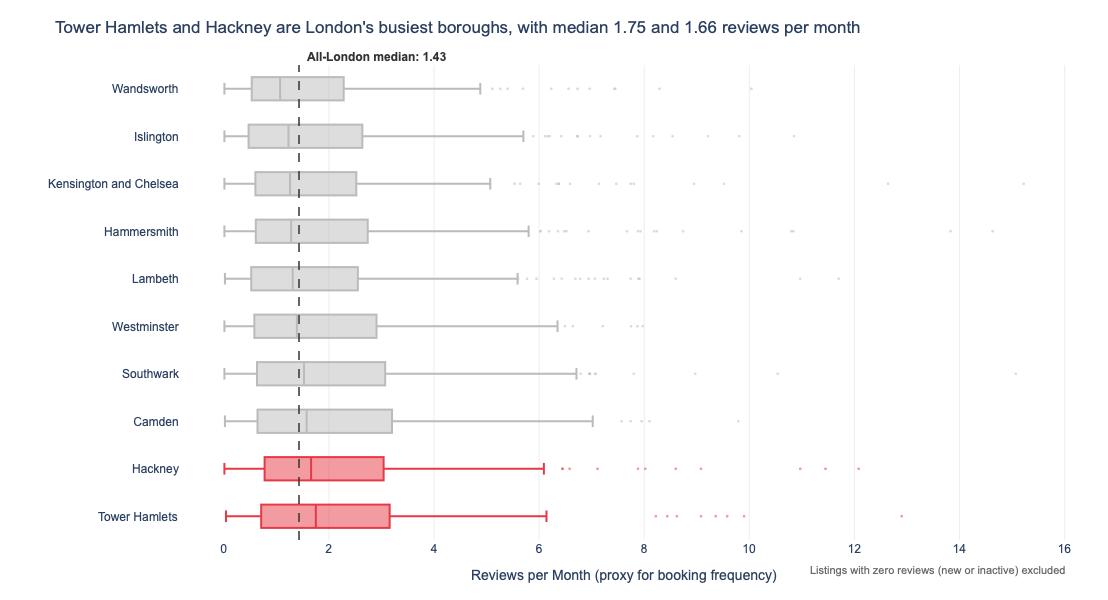

In [4]:
# Task 2 — Horizontal box plot: reviews per month by borough (active listings only)
d2 = df[df['reviews_per_month'].notna() & (df['reviews_per_month'] > 0)].copy()   # drop new/inactive listings

# Sort ascending: in a horizontal plotly box the first category is drawn at the bottom -> most active ends on top
med = d2.groupby('neighbourhood')['reviews_per_month'].median().sort_values(ascending=True)
order = med.index.tolist()
top2 = med.index[-2:][::-1].tolist()            # two most active boroughs (most active first)

# Colour has meaning: highlight the two busiest boroughs, grey for the rest
colour_map = {b: ('#E63946' if b in top2 else '#BBBBBB') for b in order}

fig = px.box(
    data_frame=d2, x='reviews_per_month', y='neighbourhood',
    color='neighbourhood', color_discrete_map=colour_map,
    category_orders={'neighbourhood': order},
    points='outliers',                              # outliers as individual points
    labels={'reviews_per_month': 'Reviews per Month (proxy for booking frequency)', 'neighbourhood': ''},
    height=max(600, 22 * len(order))
)
fig.update_traces(marker=dict(size=3, opacity=0.5))

# Reference line: overall median across all active listings
overall = d2['reviews_per_month'].median()
fig.add_vline(x=overall, line_dash='dash', line_color='#333333', line_width=1.5,
              annotation=dict(text=f'<b>All-London median: {overall:.2f}</b>', font=dict(color='#333333', size=12),
                              xanchor='left', yanchor='bottom', xshift=6))

fig.add_annotation(
    xref='paper', yref='paper', x=1, y=-0.08, showarrow=False, xanchor='right',
    text='Listings with zero reviews (new or inactive) excluded',
    font=dict(size=11, color='#666666')
)

fig.update_layout(
    title=f'{top2[0]} and {top2[1]} are London\'s busiest boroughs, with median {med[top2[0]]:.2f} and {med[top2[1]]:.2f} reviews per month',
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=12),
    xaxis=dict(gridcolor='#EEEEEE'),
    yaxis=dict(showgrid=False),
    showlegend=False,
    margin=dict(l=180, r=40, t=65, b=60)
)
fig.show()
